# Machine Learning with Tabular Data: Diabetes Readmission Prediction

## Objective and Scope

The objective is to predict the readmission status of an inpatient encounter
with a recorded diabetes diagnosis using three classes:

- `NO`: no subsequent inpatient readmission is recorded within the available data.
- `>30`: readmission occurs more than 30 days after discharge.
- `<30`: readmission occurs less than 30 days after discharge.

The prediction time is defined as **the time of discharge**. Information collected
during the hospital stay may therefore be considered if it is available when the
prediction is made. The dataset does not provide detailed recording timestamps for
individual features, so this availability remains an explicit deployment assumption.

The unit of prediction is an inpatient encounter. A patient may have multiple
encounters, but the same patient must not appear in both the training and test sets.

The primary cohort excludes encounters ending in death or discharge to hospice,
using the corresponding codes documented in `IDS_mapping.csv`. This defines the
study population; it is not a claim that hospice patients can never be readmitted.

The numerical target labels 0, 1, and 2 are class identifiers. They do not represent
numerical distance or an ordering of clinical severity.

## Workflow

1. Initial data inspection and data-quality assessment.
2. Cohort definition and patient-level train-test split.
3. Detailed EDA using the training set only.
4. Deterministic feature engineering and train-fitted preprocessing.
5. Comparison of representations with and without PCA.
6. Group-aware cross-validation and final evaluation on the held-out test set.


# Phase 1: Data Acquisition and Initial Inspection

## 1.1 Download and Extract the Dataset

In [1]:
import os
import sys
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
# Project directories
if 'google.colab' in sys.modules:
    print("Running on Google Colab")
    PROJECT_DIR = Path("/content/ml_assignment")
else:
    print("Running on Local Machine")
    PROJECT_DIR = Path.cwd() / "ml_assignment"

DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
MODULES_DIR = PROJECT_DIR / "modules"
REPORTS_DIR = PROJECT_DIR / "reports"
FEATURES_DIR = PROJECT_DIR / "features"

for d in [DATA_DIR, RAW_DIR, MODULES_DIR, REPORTS_DIR, FEATURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)
print(f"Project directory set to: {PROJECT_DIR}")

Running on Local Machine
Project directory set to: c:\Users\Luan\Downloads\ml_assignment


In [3]:
# Dowload dataset
DATA_URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"

ZIP_PATH = DATA_DIR / "diabetes.zip"

if not ZIP_PATH.exists():
    print("Downloading dataset...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    print("Download completed.")
else:
    print("Dataset archive already exists. Skipping download.")

Download completed.


In [4]:
# Extract dataset
if not list(RAW_DIR.glob("*.csv")):
    print("Extracting files...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(RAW_DIR)
    print("Extraction completed.")
else:
    print("Files already extracted.")
print("\nFiles in raw directory:")
for path in RAW_DIR.rglob("*"):
    if path.is_file():
        print(f" - {path.name}")

Extracting files...
Extraction completed.

Files in raw directory:
 - diabetic_data.csv
 - IDS_mapping.csv


## 1.2 Load the Dataset

Identifiers and diagnosis codes are loaded as strings to preserve their meaning.

Missing-value parsing is explicitly controlled. In laboratory features, the
literal value `None` represents a test that was not performed and is renamed
`NotMeasured`. It is kept separate from genuinely missing information.

The original loaded data are retained in `df_raw`, while `df` is used for
deterministic standardization and initial inspection.

In [5]:
TARGET = "readmitted"
CLASS_ORDER = ["NO", ">30", "<30"]
LAB_COLS = ["max_glu_serum", "A1Cresult"]
IDENTIFIER_COLS = ["encounter_id", "patient_nbr"]
CODE_COLS = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
]
DIAG_COLS = ["diag_1", "diag_2", "diag_3"]

data_paths = list(RAW_DIR.rglob("diabetic_data.csv"))
assert len(data_paths) == 1, "Expected exactly one diabetic_data.csv file."
DATA_PATH = data_paths[0]

# encounter_id remains numeric. The other identifiers/codes are categorical strings.
categorical_string_cols = ["patient_nbr"] + CODE_COLS + DIAG_COLS
df_raw = pd.read_csv(
    DATA_PATH,
    keep_default_na=False,
    na_values=["?", ""],
    dtype={column: object for column in categorical_string_cols},
    low_memory=False,
)

df = df_raw.copy()

# Strip whitespace without converting genuine NaN values into the string "nan".
for column in df.select_dtypes(include="object"):
    df[column] = df[column].str.strip()

# "None" means the test was not ordered/performed, not an unknown data value.
for column in LAB_COLS:
    df[column] = df[column].replace({"None": "NotMeasured"})

assert df[TARGET].notna().all(), "The target contains missing values."
assert set(df[TARGET].unique()) <= set(CLASS_ORDER), "Unexpected target class found."
assert df[IDENTIFIER_COLS].notna().all().all(), "An identifier is missing."

print("Dataset shape:", df.shape)
display(df[LAB_COLS].head())


C:\Users\Luan\AppData\Local\Temp\ipykernel_24048\733332676.py:29: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include="object"):


Dataset shape: (101766, 50)


,max_glu_serum,A1Cresult
0,NotMeasured,NotMeasured
1,NotMeasured,NotMeasured
2,NotMeasured,NotMeasured
3,NotMeasured,NotMeasured
4,NotMeasured,NotMeasured


In [6]:
print(f"Dataset shape:{df.shape}") # 50 features and 101766 samples
print(f"Number of rows:{df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Dataset shape:(101766, 50)
Number of rows:101,766
Number of columns: 50


In [7]:
# Columns names
print("COLUMN NAMES")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:2d}. {col}")

COLUMN NAMES
 1. encounter_id
 2. patient_nbr
 3. race
 4. gender
 5. age
 6. weight
 7. admission_type_id
 8. discharge_disposition_id
 9. admission_source_id
10. time_in_hospital
11. payer_code
12. medical_specialty
13. num_lab_procedures
14. num_procedures
15. num_medications
16. number_outpatient
17. number_emergency
18. number_inpatient
19. diag_1
20. diag_2
21. diag_3
22. number_diagnoses
23. max_glu_serum
24. A1Cresult
25. metformin
26. repaglinide
27. nateglinide
28. chlorpropamide
29. glimepiride
30. acetohexamide
31. glipizide
32. glyburide
33. tolbutamide
34. pioglitazone
35. rosiglitazone
36. acarbose
37. miglitol
38. troglitazone
39. tolazamide
40. examide
41. citoglipton
42. insulin
43. glyburide-metformin
44. glipizide-metformin
45. glimepiride-pioglitazone
46. metformin-rosiglitazone
47. metformin-pioglitazone
48. change
49. diabetesMed
50. readmitted


In [8]:
# Print first 5 rows
display(df.head())

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [9]:
# Data type
display(df.dtypes.to_frame(name="dtype"))

,dtype
encounter_id,int64
patient_nbr,object
race,str
gender,str
age,str
weight,str
admission_type_id,object
discharge_disposition_id,object
admission_source_id,object
time_in_hospital,int64


## 1.3 Initial Data Quality Assessment

This section describes the structure and basic quality of the complete dataset.

It distinguishes:

- Missing information from the NotMeasured laboratory state.
- Fully duplicated rows from repeated encounters belonging to the same patient.
- Identifier columns from predictive features.

A repeated patient identifier does not automatically indicate a duplicate record.
It indicates that the patient has multiple recorded encounters.

In [10]:
print("=" * 60)
print("DATASET OVERVIEW - NUMERICAL & CATEGORICAL")
print("=" * 60)

# Keep encounter_id numeric so chronological sorting remains numeric later.
# Categorical ID columns are converted to strings to avoid treating them as measurements.
id_cols = ['patient_nbr', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id']
df[id_cols] = df[id_cols].astype(str)

# Observe overall distribution
display(df.describe(include="all").T)

DATASET OVERVIEW - NUMERICAL & CATEGORICAL


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,NaN,NaN,NaN,165201645.622978,102640295.983457,12522.0,84961194.0,152388987.0,230270887.5,443867222.0
patient_nbr,101766,71518,88785891,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,99493,5,Caucasian,76099,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,101766,3,Female,54708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,101766,10,[70-80),26068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,3197,9,[75-100),1336,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_type_id,101766,8,1,53990,NaN,NaN,NaN,NaN,NaN,NaN,NaN
discharge_disposition_id,101766,26,1,60234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_source_id,101766,17,7,57494,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time_in_hospital,101766.0,NaN,NaN,NaN,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0


## 1.4 Missing Value Analysis

In [11]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100,
}).sort_values("missing_pct", ascending=False)

print("Missing information:")
display(missing_summary.query("missing_count > 0").round(2))

lab_status_summary = pd.DataFrame({
    "not_measured_count": [
        df[col].eq("NotMeasured").sum() for col in LAB_COLS
    ],
    "not_measured_pct": [
        df[col].eq("NotMeasured").mean() * 100 for col in LAB_COLS
    ],
    "missing_count": [
        df[col].isna().sum() for col in LAB_COLS
    ],
}, index=LAB_COLS)

print("Laboratory test availability:")
display(lab_status_summary.round(2))

visits_per_patient = df.groupby("patient_nbr").size()

print("Fully duplicated rows:", df.duplicated().sum())
print("Repeated encounter IDs:", df["encounter_id"].duplicated().sum())
print("Unique patients:", visits_per_patient.size)
print("Patients with multiple encounters:", visits_per_patient.gt(1).sum())
print("Encounters beyond one per patient:", (visits_per_patient - 1).sum())

display(visits_per_patient.describe().to_frame("encounters_per_patient"))

Missing information:


,missing_count,missing_pct
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


Laboratory test availability:


,not_measured_count,not_measured_pct,missing_count
max_glu_serum,96420,94.75,0
A1Cresult,84748,83.28,0


Fully duplicated rows: 0
Repeated encounter IDs: 0
Unique patients: 71518
Patients with multiple encounters: 16773
Encounters beyond one per patient: 30248


,encounters_per_patient
count,71518.000000
mean,1.422942
std,1.090740
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,40.000000


## 1.5 Duplicate Analysis

In [12]:
print("=" * 60)
print("DUPLICATE & PATIENT ENCOUNTER ANALYSIS")
print("=" * 60)

# Check for completely duplicated rows
duplicate_count = df.duplicated().sum()
print(f"Total fully duplicated rows: {duplicate_count}")

# BONUS: Check if a single patient has multiple encounters (readmissions)
unique_patients = df['patient_nbr'].nunique()
total_encounters = len(df)
multiple_encounters = total_encounters - unique_patients

print(f"Total encounters (rows): {total_encounters:,}")
print(f"Total unique patients: {unique_patients:,}")
print(f"Number of return visits (multiple encounters): {multiple_encounters:,}")


DUPLICATE & PATIENT ENCOUNTER ANALYSIS
Total fully duplicated rows: 0
Total encounters (rows): 101,766
Total unique patients: 71,518
Number of return visits (multiple encounters): 30,248


## 1.6 Target Distribution

In [13]:
TARGET = "readmitted"

# Count each target class
target_counts = df[TARGET].value_counts()

# Calculate percentages
target_percentages = df[TARGET].value_counts(normalize=True) * 100

# Combine into one summary table
target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percentages
})

print("=" * 60)
print("TARGET DISTRIBUTION")
print("=" * 60)

display(target_summary)

TARGET DISTRIBUTION


,count,percentage
readmitted,,
NO,54864,53.911916
>30,35545,34.928169
<30,11357,11.159916


Target Distribution Visualization

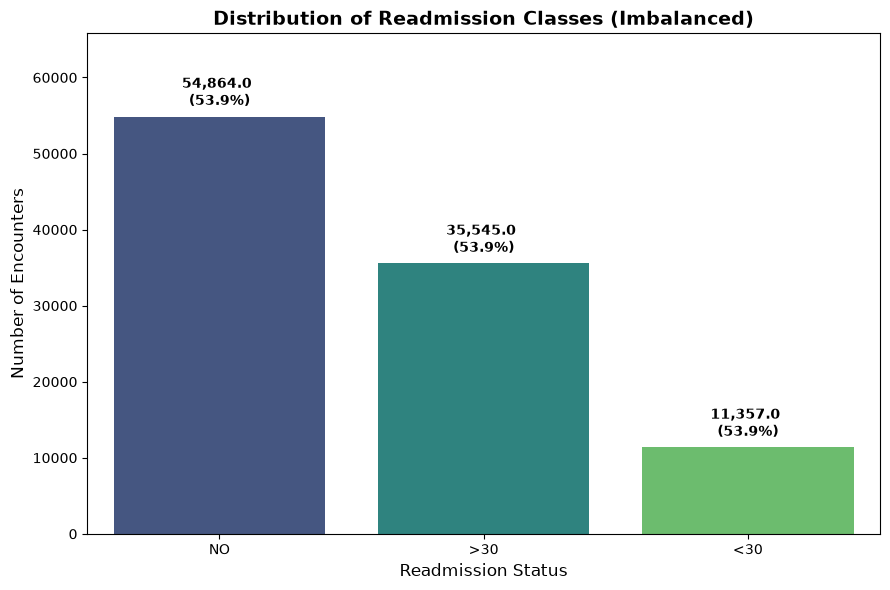

In [14]:
# Visualization
plt.figure(figsize=(9, 6))
# Use 'viridis' palette for better aesthetic, assign x to hue to avoid warnings

ax = sns.countplot(data=df, x=TARGET, order=target_counts.index, hue=TARGET, palette='viridis', legend=False)
plt.title("Distribution of Readmission Classes (Imbalanced)", fontsize=14, fontweight='bold')
plt.xlabel("Readmission Status", fontsize=12)
plt.ylabel("Number of Encounters", fontsize=12)

# Add both count and percentage labels on top of the bars
for i, container in enumerate(ax.containers):
    labels = [f'{v.get_height():,} \n({target_percentages.iloc[j]:.1f}%)' for j, v in enumerate(container)]
    ax.bar_label(container, labels=labels, padding=5, fontweight='bold')

# Expand y-axis slightly to fit the tall labels
plt.ylim(0, target_counts.max() * 1.2)
plt.tight_layout()
plt.show()

# Phase 2: Cohort Definition and Patient-Level Holdout Split

The primary analysis excludes encounters ending in death or discharge to hospice,
according to the supplied ID mapping. All other eligible encounters are retained.

The holdout split is performed by `patient_nbr` before detailed EDA. Several
Group Shuffle Split candidates are generated, and the candidate closest to the
overall class distribution is selected. This approximates stratification while
preserving complete patient separation.


In [15]:
from sklearn.model_selection import GroupShuffleSplit

DEAD_HOSPICE_IDS = {"11", "13", "14", "19", "20", "21"}

df_cohort = df.loc[
    ~df["discharge_disposition_id"].isin(DEAD_HOSPICE_IDS)
].copy()

print("Original encounters:", f"{len(df):,}")
print("Eligible encounters:", f"{len(df_cohort):,}")
print("Excluded death/hospice encounters:", f"{len(df) - len(df_cohort):,}")

overall_distribution = (
    df_cohort[TARGET].value_counts(normalize=True).reindex(CLASS_ORDER, fill_value=0)
)

splitter = GroupShuffleSplit(n_splits=20, test_size=0.20, random_state=RANDOM_STATE)
split_candidates = []
for candidate_id, (candidate_train, candidate_test) in enumerate(
    splitter.split(df_cohort, df_cohort[TARGET], groups=df_cohort["patient_nbr"])
):
    test_distribution = (
        df_cohort.iloc[candidate_test][TARGET]
        .value_counts(normalize=True)
        .reindex(CLASS_ORDER, fill_value=0)
    )
    class_gap = (test_distribution - overall_distribution).abs().sum()
    size_gap = abs(len(candidate_test) / len(df_cohort) - 0.20)
    split_candidates.append((class_gap + size_gap, candidate_id, candidate_train, candidate_test))

_, selected_candidate, train_positions, test_positions = min(
    split_candidates, key=lambda item: item[0]
)

df_train_raw = df_cohort.iloc[train_positions].copy()
df_test_raw = df_cohort.iloc[test_positions].copy()

train_patients = set(df_train_raw["patient_nbr"])
test_patients = set(df_test_raw["patient_nbr"])
patient_overlap = train_patients.intersection(test_patients)
assert not patient_overlap, "Patient leakage detected between train and test."

split_distribution = pd.concat({
    "cohort_pct": overall_distribution * 100,
    "train_pct": df_train_raw[TARGET].value_counts(normalize=True).reindex(CLASS_ORDER) * 100,
    "test_pct": df_test_raw[TARGET].value_counts(normalize=True).reindex(CLASS_ORDER) * 100,
}, axis=1)

print("Selected GroupShuffleSplit candidate:", selected_candidate)
print("Train encounters / patients:", f"{len(df_train_raw):,}", f"/ {len(train_patients):,}")
print("Test encounters / patients:", f"{len(df_test_raw):,}", f"/ {len(test_patients):,}")
print("Patient overlap:", len(patient_overlap))
display(split_distribution.round(2))

# All detailed EDA below uses only the training partition.
eda_df = df_train_raw


Original encounters: 101,766
Eligible encounters: 99,343
Excluded death/hospice encounters: 2,423
Selected GroupShuffleSplit candidate: 18
Train encounters / patients: 79,512 / 55,992
Test encounters / patients: 19,831 / 13,998
Patient overlap: 0


,cohort_pct,train_pct,test_pct
readmitted,,,
NO,52.87,52.88,52.86
>30,35.74,35.73,35.78
<30,11.39,11.40,11.36


# Phase 3: Exploratory Data Analysis on the Training Set

## 3.1 Categorical Features


In [16]:
TARGET = "readmitted"

print("=" * 60)
print("TRAINING-SET CATEGORICAL SUMMARY")
print("=" * 60)

categorical_cols = eda_df.select_dtypes(include=["object", "string"]).columns.tolist()
excluded_cols = [TARGET, "encounter_id", "patient_nbr"]
categorical_features_eda = [c for c in categorical_cols if c not in excluded_cols]

cat_summary_rows = []
for column in categorical_features_eda:
    values = eda_df[column].fillna("Missing")
    counts = values.value_counts()
    cat_summary_rows.append({
        "feature": column,
        "unique_values": values.nunique(),
        "dominant_value": counts.index[0],
        "dominant_pct": counts.iloc[0] / len(eda_df) * 100,
    })

cat_summary = pd.DataFrame(cat_summary_rows).sort_values("dominant_pct", ascending=False)
display(cat_summary.round(2))

near_constant_eda = cat_summary.query("dominant_pct > 95")
print(f"Near-constant candidates (>95% dominant): {len(near_constant_eda)}")
print("These are candidates for validation, not automatically useless features.")


TRAINING-SET CATEGORICAL SUMMARY


,feature,unique_values,dominant_value,dominant_pct
30,citoglipton,1,No,100.00
29,examide,1,No,100.00
19,acetohexamide,2,No,100.00
36,metformin-pioglitazone,2,No,100.00
34,glimepiride-pioglitazone,2,No,100.00
35,metformin-rosiglitazone,2,No,100.00
27,troglitazone,2,No,100.00
33,glipizide-metformin,2,No,99.99
22,tolbutamide,2,No,99.98
28,tolazamide,3,No,99.96


Near-constant candidates (>95% dominant): 17
These are candidates for validation, not automatically useless features.


DISTRIBUTION OF KEY CATEGORICAL FEATURES - TRAINING SET


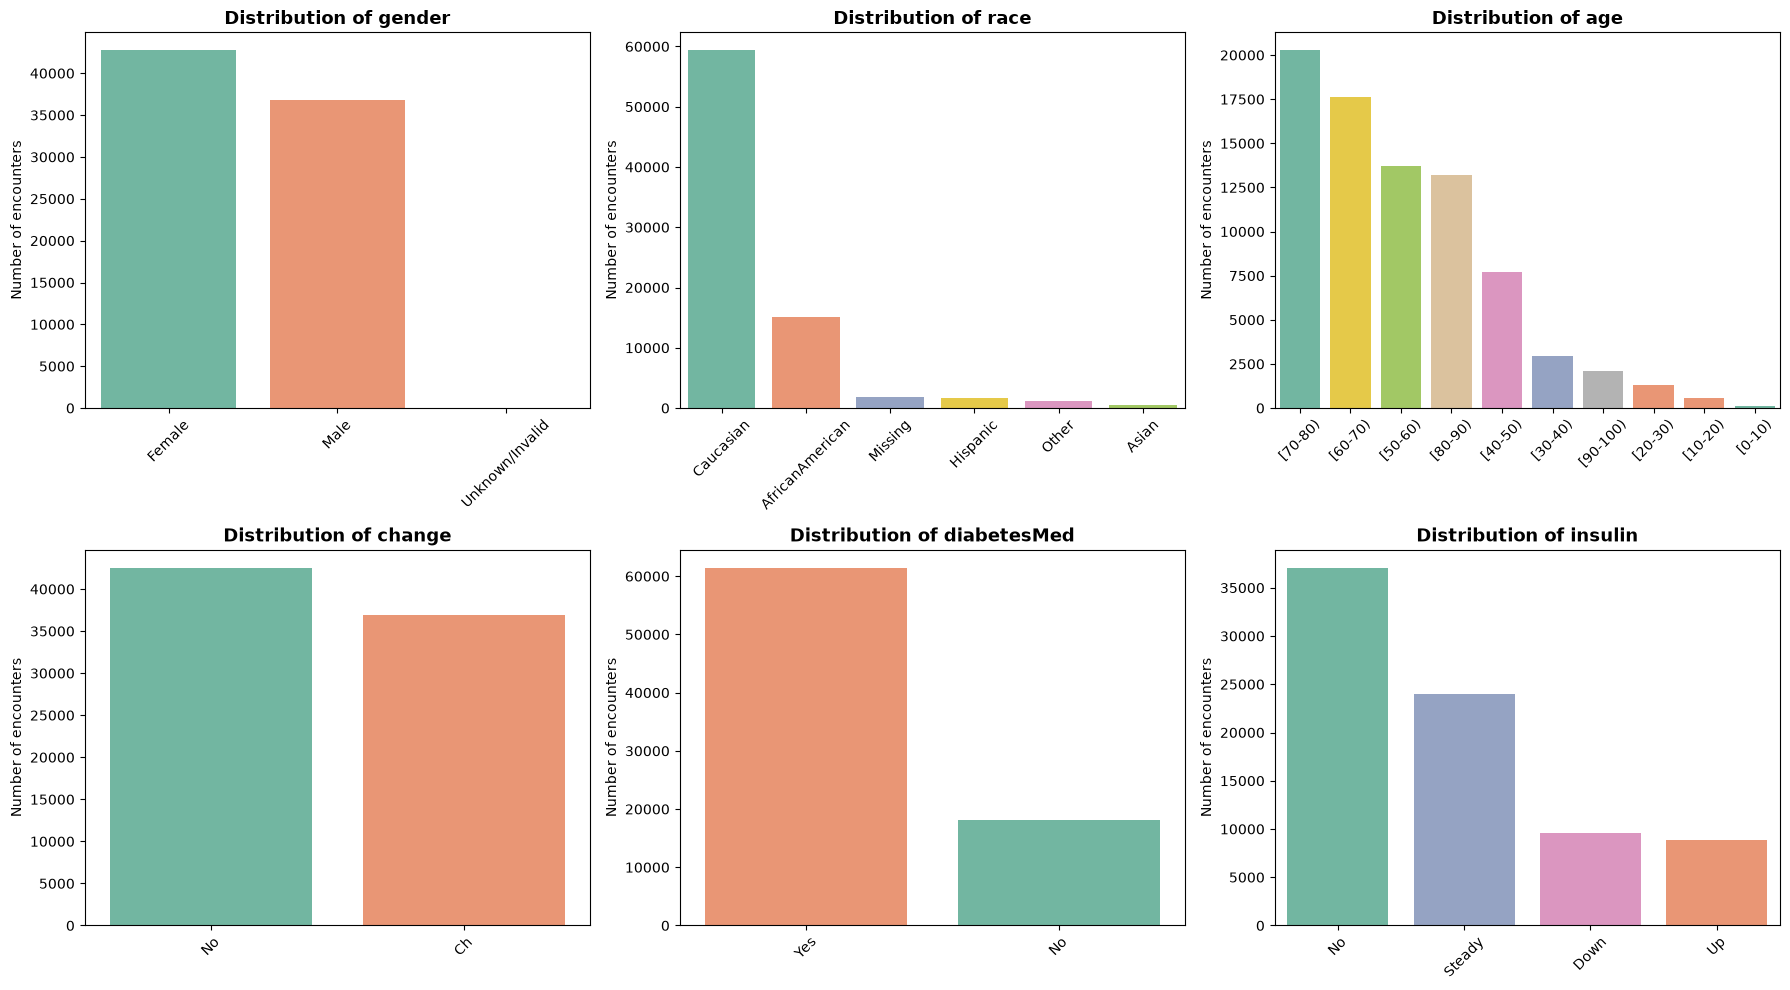

In [17]:
print("=" * 60)
print("DISTRIBUTION OF KEY CATEGORICAL FEATURES - TRAINING SET")
print("=" * 60)

key_categorical_features = ["gender", "race", "age", "change", "diabetesMed", "insulin"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for axis, column in zip(axes, key_categorical_features):
    plot_data = eda_df[column].fillna("Missing").astype(str)
    sns.countplot(
        x=plot_data,
        order=plot_data.value_counts().index,
        hue=plot_data,
        palette="Set2",
        legend=False,
        ax=axis,
    )
    axis.set_title(f"Distribution of {column}", fontsize=13, fontweight="bold")
    axis.set_xlabel("")
    axis.set_ylabel("Number of encounters")
    axis.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


## 3.2 Numerical Features and Outliers


NUMERICAL DISTRIBUTIONS AND OUTLIERS - TRAINING SET


,feature,skewness,iqr_outlier_pct,median
5,number_emergency,10.99,11.25,0.0
4,number_outpatient,8.81,16.43,0.0
6,number_inpatient,3.66,6.87,0.0
3,num_medications,1.34,2.48,15.0
2,num_procedures,1.32,4.81,1.0
0,time_in_hospital,1.14,2.14,4.0
7,number_diagnoses,-0.86,0.28,8.0
1,num_lab_procedures,-0.24,0.12,44.0


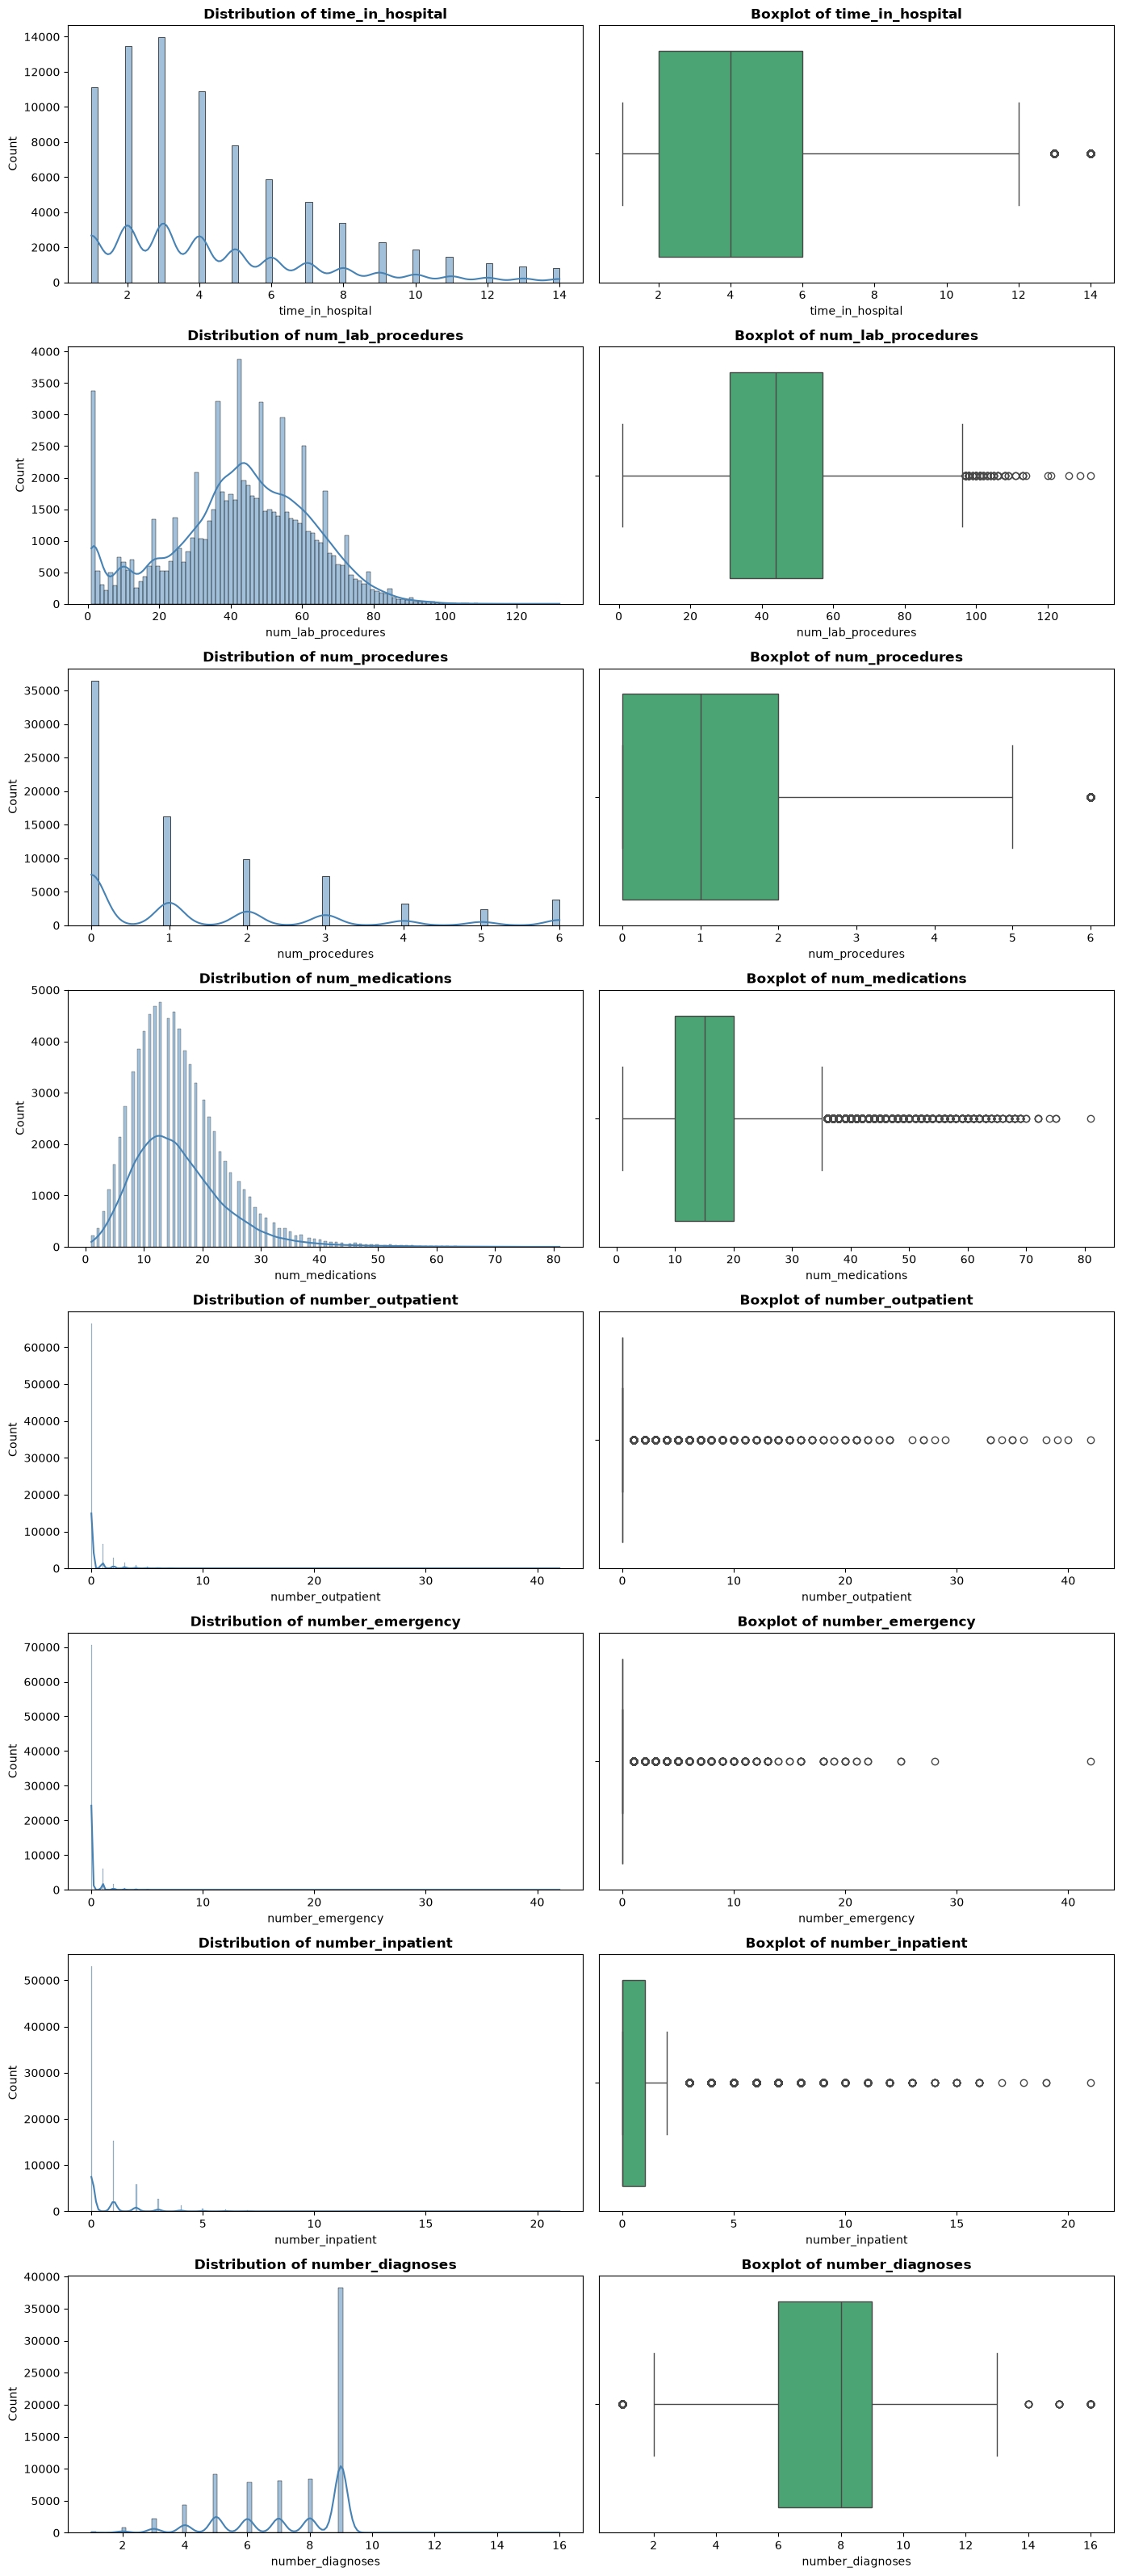

In [18]:
print("=" * 60)
print("NUMERICAL DISTRIBUTIONS AND OUTLIERS - TRAINING SET")
print("=" * 60)

numerical_cols = [
    column for column in eda_df.select_dtypes(include=["int64", "float64"]).columns
    if column != "encounter_id"
]

numeric_summary_rows = []
for column in numerical_cols:
    values = eda_df[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_mask = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    numeric_summary_rows.append({
        "feature": column,
        "skewness": values.skew(),
        "iqr_outlier_pct": outlier_mask.mean() * 100,
        "median": values.median(),
    })

numeric_summary = pd.DataFrame(numeric_summary_rows).sort_values(
    "skewness", key=lambda series: series.abs(), ascending=False
)
display(numeric_summary.round(2))

fig, axes = plt.subplots(len(numerical_cols), 2, figsize=(14, 4 * len(numerical_cols)))
for row, column in enumerate(numerical_cols):
    sns.histplot(eda_df[column], kde=True, ax=axes[row, 0], color="steelblue")
    axes[row, 0].set_title(f"Distribution of {column}", fontweight="bold")
    sns.boxplot(x=eda_df[column], ax=axes[row, 1], color="mediumseagreen")
    axes[row, 1].set_title(f"Boxplot of {column}", fontweight="bold")

plt.tight_layout()
plt.show()


## 3.3 Numerical Correlation


NUMERICAL CORRELATION - TRAINING SET
Ten strongest pairwise correlations by absolute value:


correlation  abs_correlation
time_in_hospital   num_medications           0.465            0.465
num_procedures     num_medications           0.383            0.383
time_in_hospital   num_lab_procedures        0.319            0.319
number_emergency   number_inpatient          0.297            0.297
num_lab_procedures num_medications           0.267            0.267
num_medications    number_diagnoses          0.261            0.261
time_in_hospital   number_diagnoses          0.220            0.220
                   num_procedures            0.191            0.191
num_lab_procedures number_diagnoses          0.152            0.152
number_outpatient  number_inpatient          0.108            0.108

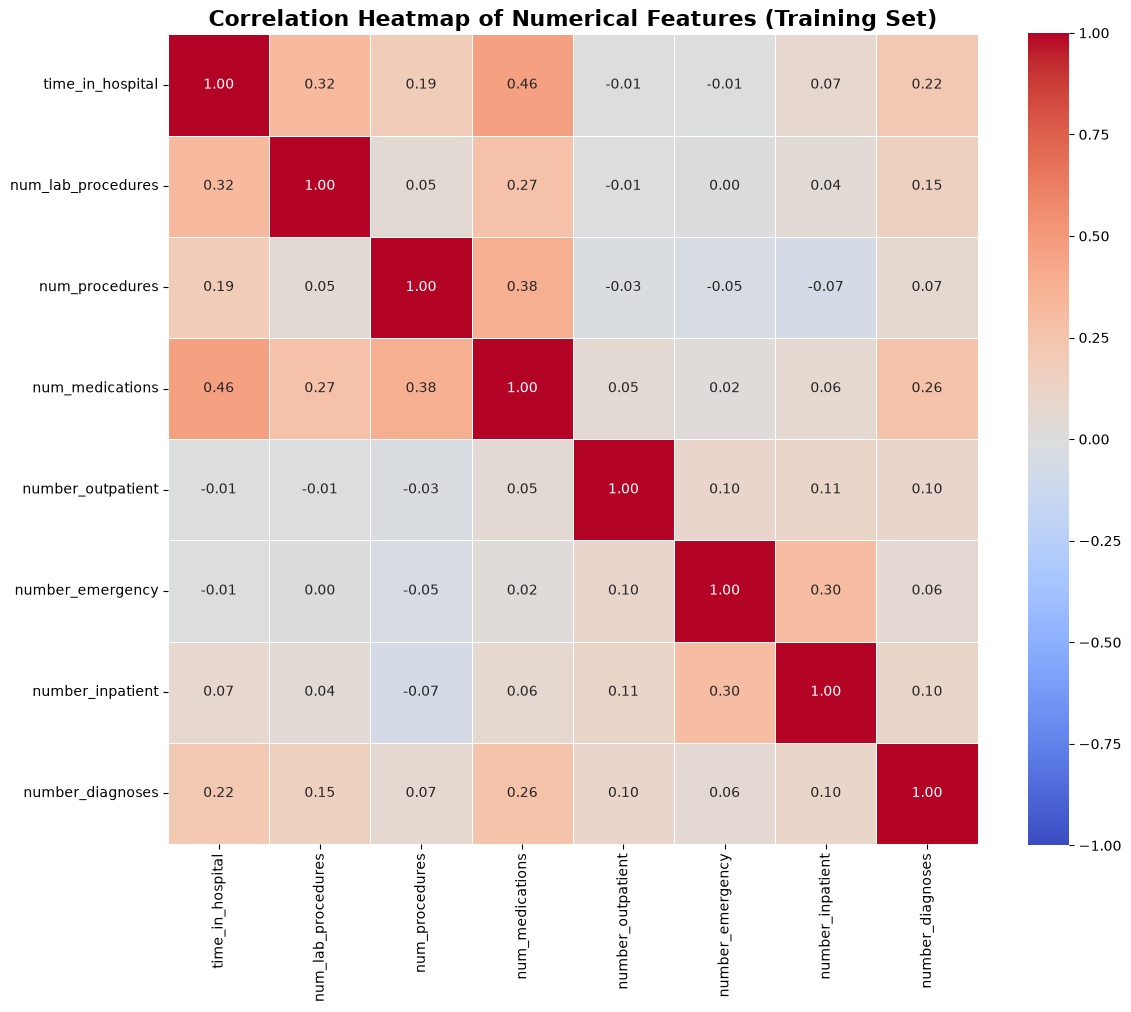

In [19]:
print("=" * 60)
print("NUMERICAL CORRELATION - TRAINING SET")
print("=" * 60)

corr_matrix = eda_df[numerical_cols].corr()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
top_correlations = (
    upper_triangle.stack()
    .rename("correlation")
    .to_frame()
    .assign(abs_correlation=lambda table: table["correlation"].abs())
    .sort_values("abs_correlation", ascending=False)
    .head(10)
)

print("Ten strongest pairwise correlations by absolute value:")
display(top_correlations.round(3))

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
)
plt.title("Correlation Heatmap of Numerical Features (Training Set)", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()


BIVARIATE ANALYSIS - TRAINING SET
Time in hospital by target class:


,count,mean,median,std
readmitted,,,,
NO,42044,4.22,3.0,2.93
>30,28406,4.49,4.0,2.99
<30,9062,4.78,4.0,3.04


Target percentages within each age group:


readmitted,NO,>30,<30
age,,,
[0-10),82.58,15.15,2.27
[10-20),60.61,32.91,6.47
[20-30),55.17,30.40,14.44
[30-40),57.97,31.30,10.73
[40-50),55.10,34.28,10.61
[50-60),55.61,34.69,9.70
[60-70),53.06,35.83,11.11
[70-80),50.61,37.20,12.19
[80-90),49.28,37.86,12.86


Target percentages within each gender group:


...

readmitted,NO,>30,<30
race,,,
AfricanAmerican,53.14,35.31,11.55
Asian,63.94,25.16,10.90
Caucasian,52.01,36.46,11.53
Hispanic,57.24,32.37,10.39
Missing,67.81,24.12,8.08
Other,60.03,30.61,9.36


Target percentages within each insulin group:


readmitted,NO,>30,<30
insulin,,,
Down,46.45,39.22,14.34
No,55.43,34.43,10.13
Steady,53.83,34.84,11.33
Up,46.56,39.75,13.69


Target percentages within each A1Cresult group:


readmitted,NO,>30,<30
A1Cresult,,,
>7,55.57,34.06,10.38
>8,54.50,35.75,9.75
Norm,58.13,31.94,9.93
NotMeasured,52.28,36.03,11.70


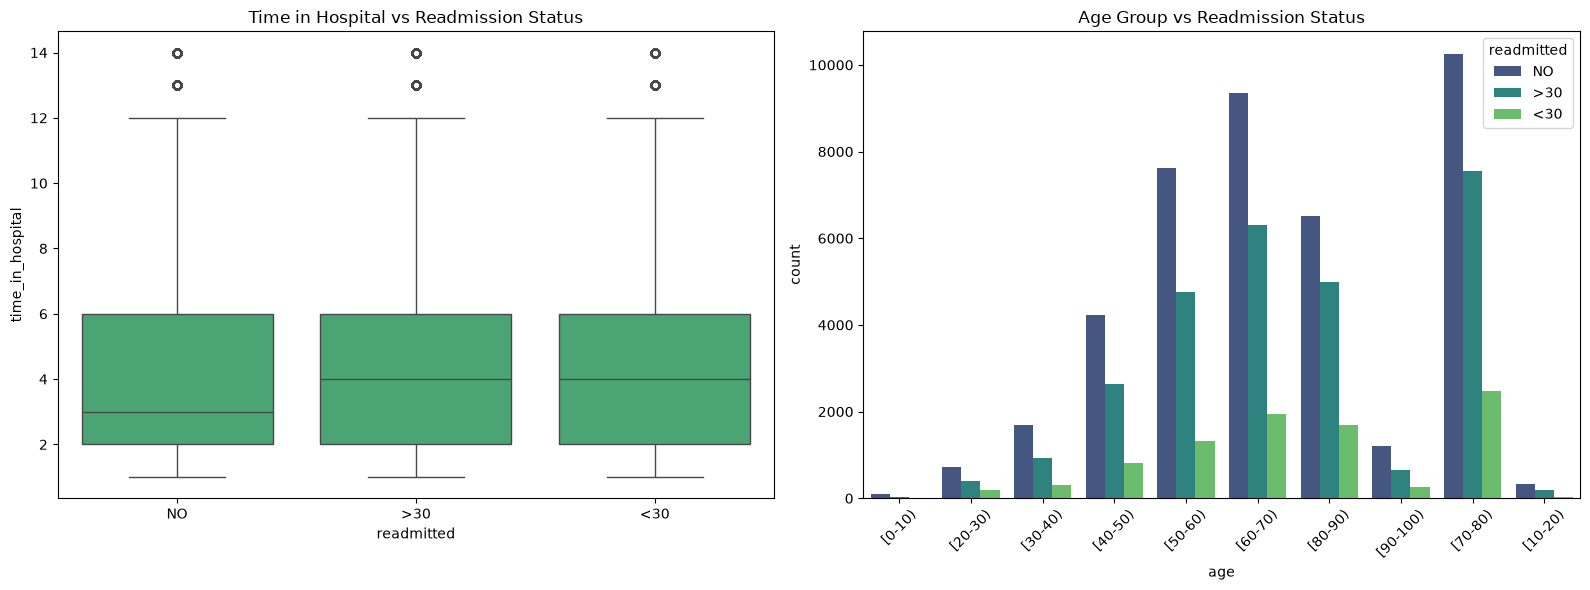

In [20]:
print("=" * 60)
print("BIVARIATE ANALYSIS - TRAINING SET")
print("=" * 60)

time_summary = eda_df.groupby(TARGET, observed=False)["time_in_hospital"].agg(
    count="size", mean="mean", median="median", std="std"
).reindex(CLASS_ORDER)
print("Time in hospital by target class:")
display(time_summary.round(2))

def target_rate_table(data, feature):
    values = data[feature].fillna("Missing")
    table = pd.crosstab(values, data[TARGET], normalize="index")
    return (table.reindex(columns=CLASS_ORDER, fill_value=0) * 100).round(2)

for feature in ["age", "gender", "race", "insulin", "A1Cresult"]:
    print(f"Target percentages within each {feature} group:")
    display(target_rate_table(eda_df, feature))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=eda_df, x=TARGET, y="time_in_hospital", order=CLASS_ORDER,
            color="mediumseagreen", ax=axes[0])
axes[0].set_title("Time in Hospital vs Readmission Status")

sns.countplot(data=eda_df, x="age", hue=TARGET, hue_order=CLASS_ORDER,
              palette="viridis", ax=axes[1])
axes[1].set_title("Age Group vs Readmission Status")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


## 3.5 EDA Summary and Decisions

### Finding 1 - The target is meaningfully, but not extremely, imbalanced

`<30` is the smallest and most operationally important class. Class proportions are
reported for the full cohort and both patient-disjoint splits.

**Interpretation:** Accuracy alone can hide poor detection of early readmission.

**Action:** Report macro-F1, weighted-F1, the confusion matrix, and precision/recall/F1
for `<30`. Multiclass ROC-AUC or PR-AUC must state the One-vs-Rest and averaging scheme.

### Finding 2 - Repeated patients create a leakage risk, not automatic leakage

Multiple encounters from one patient are valid observations. Leakage occurs if the
same patient is present in both training and test data.

**Action:** Retain all eligible encounters and split by `patient_nbr`. Keep patient IDs
only for grouping; never expose them to the model. Use group-aware cross-validation.

### Finding 3 - Missingness and non-measurement are not always equivalent

`weight` has very little observed information. `max_glu_serum` and `A1Cresult` are often
not measured, which may describe the care process rather than a recording error.

**Action:** Drop `weight`, preserve `NotMeasured` as an explicit laboratory state, and
impute genuinely missing categorical values inside the training pipeline.

### Finding 4 - Low variance does not prove that a feature has no signal

Some medication columns are constant or nearly constant. Rare values can still be
associated with the rare `<30` outcome.

**Action:** Drop only zero-variance columns by default. Treat near-constant columns as
experiment candidates and compare model performance before removing them.

### Finding 5 - Prediction time determines whether a feature is valid

This notebook assumes prediction at discharge, so information available by discharge
may be used. In an admission-time deployment, fields such as
`discharge_disposition_id` would be future information and must be removed.

### Finding 6 - Visual counts must be separated from within-group risk

Large groups naturally produce more readmissions in count plots.

**Action:** Use within-group target percentages, sample sizes, numerical summaries,
and correlation tables alongside visualizations. Differences observed in EDA are
descriptive and are not evidence of causality.


# Phase 4: Data Preprocessing

The held-out test set was created before detailed EDA. Deterministic cleaning rules
are now applied consistently to the training and test frames. All data-dependent
operations, including imputation, rare-category grouping, scaling, feature selection,
and PCA, are fitted using training data only.


## 4.1 Initialize the Patient-Disjoint Splits


In [21]:
print("=" * 60)
print("INITIALIZE CLEAN TRAIN AND TEST FRAMES")
print("=" * 60)

df_train_clean = df_train_raw.copy()
df_test_clean = df_test_raw.copy()

print(f"Training encounters: {len(df_train_clean):,}")
print(f"Test encounters: {len(df_test_clean):,}")
print("Repeated encounters are retained; patient groups remain disjoint.")


INITIALIZE CLEAN TRAIN AND TEST FRAMES
Training encounters: 79,512
Test encounters: 19,831
Repeated encounters are retained; patient groups remain disjoint.


## 4.2 Remove Non-Predictive and Unusable Columns


In [22]:
print("=" * 60)
print("DROP NON-PREDICTIVE AND HEAVILY MISSING COLUMNS")
print("=" * 60)

# patient_nbr is deliberately retained until X/y/groups are separated.
columns_to_drop = ["encounter_id", "weight"]
df_train_clean = df_train_clean.drop(columns=columns_to_drop, errors="ignore")
df_test_clean = df_test_clean.drop(columns=columns_to_drop, errors="ignore")

print("Dropped from both splits:", columns_to_drop)
print("patient_nbr retained temporarily for grouped validation.")
print("Train shape:", df_train_clean.shape)
print("Test shape:", df_test_clean.shape)


DROP NON-PREDICTIVE AND HEAVILY MISSING COLUMNS
Dropped from both splits: ['encounter_id', 'weight']
patient_nbr retained temporarily for grouped validation.
Train shape: (79512, 48)
Test shape: (19831, 48)


In [23]:
print("=" * 60)
print("LOW-VARIANCE AUDIT ON TRAINING DATA")
print("=" * 60)

audit_features = [
    column for column in df_train_clean.columns
    if column not in {TARGET, "patient_nbr"}
]

variance_audit_rows = []
for column in audit_features:
    counts = df_train_clean[column].value_counts(dropna=False)
    variance_audit_rows.append({
        "feature": column,
        "unique_values": df_train_clean[column].nunique(dropna=False),
        "dominant_pct": counts.iloc[0] / len(df_train_clean) * 100,
    })

variance_audit = pd.DataFrame(variance_audit_rows).sort_values("dominant_pct", ascending=False)
constant_candidates = variance_audit.query("unique_values <= 1")["feature"].tolist()
near_constant_candidates = variance_audit.query(
    "unique_values > 1 and dominant_pct > 95"
)["feature"].tolist()

display(variance_audit.head(25).round(2))
print("Zero-variance columns to drop:", constant_candidates)
print("Near-constant columns retained for comparison:", near_constant_candidates)


LOW-VARIANCE AUDIT ON TRAINING DATA


,feature,unique_values,dominant_pct
36,examide,1,100.00
37,citoglipton,1,100.00
43,metformin-pioglitazone,2,100.00
26,acetohexamide,2,100.00
41,glimepiride-pioglitazone,2,100.00
42,metformin-rosiglitazone,2,100.00
34,troglitazone,2,100.00
40,glipizide-metformin,2,99.99
29,tolbutamide,2,99.98
35,tolazamide,3,99.96


Zero-variance columns to drop: ['examide', 'citoglipton']
Near-constant columns retained for comparison: ['metformin-pioglitazone', 'acetohexamide', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'troglitazone', 'glipizide-metformin', 'tolbutamide', 'tolazamide', 'miglitol', 'chlorpropamide', 'acarbose', 'nateglinide', 'glyburide-metformin', 'repaglinide']


In [24]:
print("=" * 60)
print("CURRENT STATE BEFORE MISSING-CODE STANDARDIZATION")
print("=" * 60)

print(f"Training data: {df_train_clean.shape[0]:,} rows, {df_train_clean.shape[1]} columns")
print(f"Test data:     {df_test_clean.shape[0]:,} rows, {df_test_clean.shape[1]} columns")

train_missing = pd.DataFrame({
    "missing_count": df_train_clean.isna().sum(),
    "missing_pct": df_train_clean.isna().mean() * 100,
}).query("missing_count > 0").sort_values("missing_pct", ascending=False)

display(train_missing.round(2))


CURRENT STATE BEFORE MISSING-CODE STANDARDIZATION
Training data: 79,512 rows, 48 columns
Test data:     19,831 rows, 48 columns


,missing_count,missing_pct
medical_specialty,38745,48.73
payer_code,31438,39.54
race,1808,2.27
diag_3,1129,1.42
diag_2,295,0.37
diag_1,17,0.02


## 4.3 Standardize Hidden Missing Codes


In [25]:
print("STANDARDIZING HIDDEN MISSING CODES")

invalid_code_map = {
    "admission_type_id": ["5", "6", "8"],
    "discharge_disposition_id": ["18", "25", "26"],
    "admission_source_id": ["9", "15", "17", "20", "21"],
}

def standardize_hidden_missing(frame):
    result = frame.copy()
    for column, invalid_codes in invalid_code_map.items():
        result[column] = result[column].replace(invalid_codes, np.nan)
    return result

df_train_clean = standardize_hidden_missing(df_train_clean)
df_test_clean = standardize_hidden_missing(df_test_clean)


STANDARDIZING HIDDEN MISSING CODES


In [26]:
missing_summary = pd.DataFrame({
    "missing_count": df_train_clean.isna().sum(),
    "missing_pct": df_train_clean.isna().mean() * 100,
}).query("missing_count > 0").sort_values("missing_pct", ascending=False)

print("Training-set missing values after hidden-code standardization:")
display(missing_summary.round(2))

print("Laboratory states are retained separately from genuine missing values:")
display(pd.DataFrame({
    "not_measured_pct": [df_train_clean[c].eq("NotMeasured").mean() * 100 for c in LAB_COLS],
    "missing_pct": [df_train_clean[c].isna().mean() * 100 for c in LAB_COLS],
}, index=LAB_COLS).round(2))

print("No imputer is fitted here; imputation remains inside the sklearn pipeline.")


Training-set missing values after hidden-code standardization:


,missing_count,missing_pct
medical_specialty,38745,48.73
payer_code,31438,39.54
admission_type_id,8099,10.19
admission_source_id,5446,6.85
discharge_disposition_id,3741,4.70
race,1808,2.27
diag_3,1129,1.42
diag_2,295,0.37
diag_1,17,0.02


Laboratory states are retained separately from genuine missing values:


,not_measured_pct,missing_pct
max_glu_serum,94.79,0.0
A1Cresult,82.93,0.0


No imputer is fitted here; imputation remains inside the sklearn pipeline.


## 4.4 Feature Engineering: Age and ICD-9


In [27]:
print("=" * 60)
print("CONFIGURABLE FEATURE ENGINEERING")
print("=" * 60)

AGE_ENCODING = "onehot"  # Alternative experiment: "midpoint"

age_mapping = {
    "[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35,
    "[40-50)": 45, "[50-60)": 55, "[60-70)": 65, "[70-80)": 75,
    "[80-90)": 85, "[90-100)": 95,
}

def map_icd9_to_category(value):
    if pd.isna(value):
        return np.nan

    code = str(value).upper()
    if code.startswith("250"):
        return "Diabetes"
    if code.startswith(("V", "E")):
        return "Supplemental"

    try:
        number = float(code)
    except ValueError:
        return "Other"

    if 390 <= number <= 459 or number == 785:
        return "Circulatory"
    if 460 <= number <= 519 or number == 786:
        return "Respiratory"
    if 520 <= number <= 579 or number == 787:
        return "Digestive"
    if 800 <= number <= 999:
        return "Injury"
    if 710 <= number <= 739:
        return "Musculoskeletal"
    if 580 <= number <= 629 or number == 788:
        return "Genitourinary"
    if 140 <= number <= 239:
        return "Neoplasms"
    return "Other"

def apply_feature_engineering(frame, age_encoding=AGE_ENCODING):
    result = frame.copy()
    if age_encoding == "midpoint":
        result["age"] = result["age"].map(age_mapping)
    elif age_encoding != "onehot":
        raise ValueError("age_encoding must be 'onehot' or 'midpoint'")

    for column in DIAG_COLS:
        result[column] = result[column].map(map_icd9_to_category)
    return result

df_train_clean = apply_feature_engineering(df_train_clean)
df_test_clean = apply_feature_engineering(df_test_clean)

print("Age representation:", AGE_ENCODING)
print("ICD-9 codes mapped to 10 categories, including Supplemental and Other.")
display(df_train_clean["diag_1"].value_counts(dropna=False).to_frame("train_count"))


CONFIGURABLE FEATURE ENGINEERING
Age representation: onehot
ICD-9 codes mapped to 10 categories, including Supplemental and Other.


,train_count
diag_1,
Circulatory,23797
Other,12905
Respiratory,11166
Digestive,7416
Diabetes,6958
Injury,5474
Genitourinary,4020
Musculoskeletal,3946
Neoplasms,2527


## 4.5 Target Encoding and Final Feature Matrices


In [28]:
print("=" * 60)
print("TARGET ENCODING AND GROUP EXTRACTION")
print("=" * 60)

target_mapping = {"NO": 0, ">30": 1, "<30": 2}
target_names = {value: key for key, value in target_mapping.items()}

groups_train = df_train_clean.pop("patient_nbr")
groups_test = df_test_clean.pop("patient_nbr")

y_train = df_train_clean.pop(TARGET).map(target_mapping)
y_test = df_test_clean.pop(TARGET).map(target_mapping)
X_train = df_train_clean.copy()
X_test = df_test_clean.copy()

assert y_train.notna().all() and y_test.notna().all()
assert set(groups_train).isdisjoint(set(groups_test))

print("Target labels are class identifiers: NO=0, >30=1, <30=2")
print("Train shapes:", X_train.shape, y_train.shape)
print("Test shapes:", X_test.shape, y_test.shape)


TARGET ENCODING AND GROUP EXTRACTION
Target labels are class identifiers: NO=0, >30=1, <30=2
Train shapes: (79512, 46) (79512,)
Test shapes: (19831, 46) (19831,)


In [29]:
from sklearn.model_selection import StratifiedGroupKFold

print("=" * 60)
print("TRAIN-ONLY FEATURE FILTER AND GROUPED CROSS-VALIDATION")
print("=" * 60)

dominance = {
    column: X_train[column].value_counts(dropna=False).iloc[0] / len(X_train)
    for column in X_train.columns
}
constant_train_cols = [
    column for column in X_train.columns
    if X_train[column].nunique(dropna=False) <= 1
]
near_constant_train_cols = [
    column for column, ratio in dominance.items()
    if ratio > 0.95 and column not in constant_train_cols
]

# Default: remove only true constants. Near-constant features remain available
# for an explicit ablation experiment instead of being assumed useless.
DROP_NEAR_CONSTANT = False
columns_to_remove = constant_train_cols + (
    near_constant_train_cols if DROP_NEAR_CONSTANT else []
)

X_train = X_train.drop(columns=columns_to_remove)
X_test = X_test.drop(columns=columns_to_remove)

group_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Dropped zero-variance columns:", constant_train_cols)
print("Retained near-constant candidates:", near_constant_train_cols)
print("Group CV:", group_cv)
print("Final raw feature shapes:", X_train.shape, X_test.shape)


TRAIN-ONLY FEATURE FILTER AND GROUPED CROSS-VALIDATION
Dropped zero-variance columns: ['examide', 'citoglipton']
Retained near-constant candidates: ['repaglinide', 'nateglinide', 'chlorpropamide', 'acetohexamide', 'tolbutamide', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']
Group CV: StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True)
Final raw feature shapes: (79512, 44) (19831, 44)


## 4.6 Configurable Preprocessing Pipeline


### 4.6.1 Numerical and Categorical Feature Groups


In [30]:
print("=" * 60)
print("DEFINE FEATURE GROUPS")
print("=" * 60)

numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

assert set(numerical_features).isdisjoint(categorical_features)
assert set(numerical_features + categorical_features) == set(X_train.columns)

print(f"Numerical features ({len(numerical_features)}):")
print(numerical_features)
print(f"Categorical features ({len(categorical_features)}):")
print(categorical_features)


DEFINE FEATURE GROUPS
Numerical features (8):
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Categorical features (36):
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


In [31]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    FunctionTransformer,
    MinMaxScaler,
    OneHotEncoder,
    RobustScaler,
    StandardScaler,
)

print("=" * 60)
print("BUILD CONFIGURABLE PREPROCESSOR")
print("=" * 60)

def get_preprocessor(
    scaler_type="standard",
    feature_range=(0, 1),
    log_numeric=False,
    min_category_frequency=20,
):
    """Build a train-fitted preprocessor for numeric and categorical columns."""
    scalers = {
        "standard": StandardScaler(),
        "robust": RobustScaler(),
        "minmax": MinMaxScaler(feature_range=feature_range),
        "none": "passthrough",
    }
    if scaler_type not in scalers:
        raise ValueError("scaler_type must be standard, robust, minmax, or none")

    numeric_steps = [("imputer", SimpleImputer(strategy="median", add_indicator=True))]
    if log_numeric:
        numeric_steps.append((
            "log1p",
            FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
        ))
    numeric_steps.append(("scaler", scalers[scaler_type]))

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=min_category_frequency,
            sparse_output=False,  # Dense output is required by the PCA comparison below.
        )),
    ])

    return ColumnTransformer(
        transformers=[
            ("num", Pipeline(numeric_steps), numerical_features),
            ("cat", categorical_pipeline, categorical_features),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

print("Available scaler options: standard, robust, minmax, none")
print("Rare categories are grouped using training-set frequency only.")


BUILD CONFIGURABLE PREPROCESSOR
Available scaler options: standard, robust, minmax, none
Rare categories are grouped using training-set frequency only.


In [32]:
print("=" * 60)
print("VALIDATE THE PREPROCESSOR")
print("=" * 60)

test_preprocessor = get_preprocessor(
    scaler_type="standard",
    log_numeric=False,
    min_category_frequency=20,
)

X_train_processed = test_preprocessor.fit_transform(X_train)
X_test_processed = test_preprocessor.transform(X_test)

assert X_train_processed.shape[1] == X_test_processed.shape[1]
assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_test_processed).all()

print("Original train shape:", X_train.shape)
print("Processed train shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)
print("No non-finite values remain after preprocessing.")


VALIDATE THE PREPROCESSOR
Original train shape: (79512, 44)
Processed train shape: (79512, 226)
Processed test shape: (19831, 226)
No non-finite values remain after preprocessing.


# Phase 5: Feature Extraction and Dimensionality Reduction

PCA is treated as an experimental representation, not a mandatory preprocessing
step. Downstream models should compare no PCA, 90% explained variance, and 95%
explained variance under the same grouped cross-validation procedure.


In [33]:
from sklearn.decomposition import PCA

print("=" * 60)
print("PCA EXPLAINED VARIANCE - TRAINING DATA ONLY")
print("=" * 60)

preprocessor_pca = get_preprocessor(
    scaler_type="standard",
    log_numeric=False,
    min_category_frequency=20,
)
X_train_pca_ready = preprocessor_pca.fit_transform(X_train)
X_test_pca_ready = preprocessor_pca.transform(X_test)

pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train_pca_ready)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
threshold_90 = np.argmax(cumulative_variance >= 0.90) + 1
threshold_95 = np.argmax(cumulative_variance >= 0.95) + 1


PCA EXPLAINED VARIANCE - TRAINING DATA ONLY


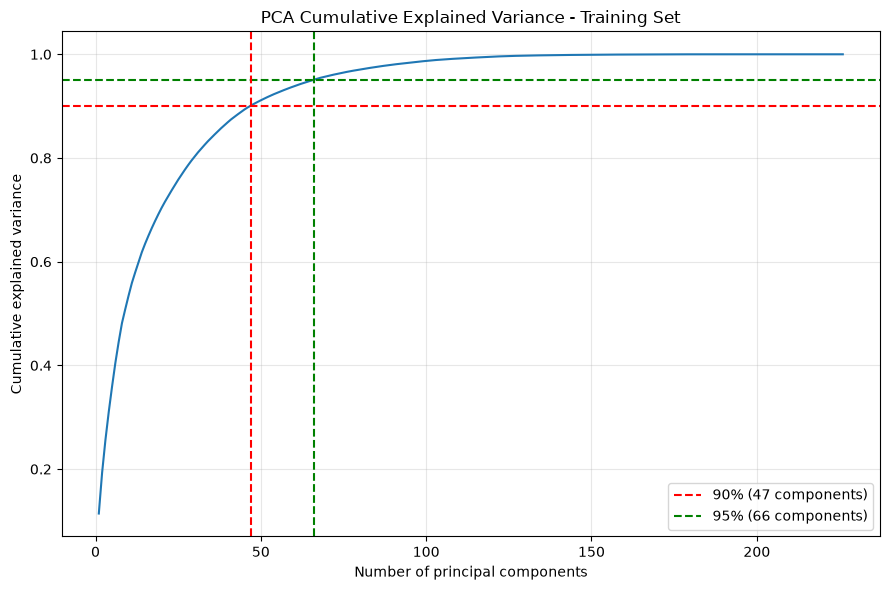

Encoded feature count: 226
Components for 90% variance: 47
Components for 95% variance: 66
Feature pipelines prepared for downstream grouped model comparison.


In [34]:
plt.figure(figsize=(9, 6))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance)
plt.axhline(0.90, color="red", linestyle="--", label=f"90% ({threshold_90} components)")
plt.axhline(0.95, color="green", linestyle="--", label=f"95% ({threshold_95} components)")
plt.axvline(threshold_90, color="red", linestyle="--")
plt.axvline(threshold_95, color="green", linestyle="--")
plt.title("PCA Cumulative Explained Variance - Training Set")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Encoded feature count:", X_train_pca_ready.shape[1])
print("Components for 90% variance:", threshold_90)
print("Components for 95% variance:", threshold_95)

def get_feature_pipeline(pca_variance=None, **preprocessor_options):
    """Create a comparable feature pipeline with optional train-fitted PCA."""
    steps = [("preprocessor", get_preprocessor(**preprocessor_options))]
    if pca_variance is not None:
        if pca_variance not in (0.90, 0.95):
            raise ValueError("pca_variance must be None, 0.90, or 0.95")
        steps.append(("pca", PCA(n_components=pca_variance, svd_solver="full")))
    return Pipeline(steps)

feature_pipeline_no_pca = get_feature_pipeline(pca_variance=None)
feature_pipeline_pca_90 = get_feature_pipeline(pca_variance=0.90)
feature_pipeline_pca_95 = get_feature_pipeline(pca_variance=0.95)

print("Feature pipelines prepared for downstream grouped model comparison.")
